In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

In [2]:
import os
print(os.getcwd())

c:\Users\Lenovo\Documents\Apple_Or_Orange_Classification


In [4]:
import zipfile
zip_path = r"c:\Users\Lenovo\Documents\Apple_Or_Orange_Classification\data.zip"
with zipfile.ZipFile(zip_path,'r')as zipref:
    zipref.extractall("data")

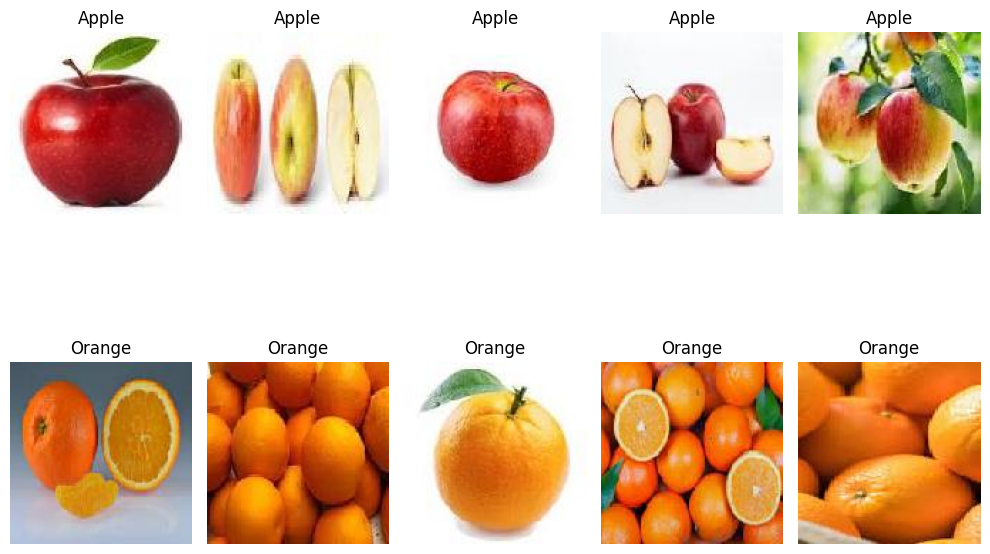

In [3]:
from PIL import Image
fruit_path={
        "Apple" : r"c:\Users\Lenovo\Documents\Apple_Or_Orange_Classification\data\fruit-dataset\apple",
        "Orange" : r"c:\Users\Lenovo\Documents\Apple_Or_Orange_Classification\data\fruit-dataset\orange"
}

position = 1
plt.figure(figsize=(10,8))
for fruits,path in (fruit_path.items()):
    files = os.listdir(path)[:5]
    for i ,file in enumerate(files):
        img_path = os.path.join(path,file)
        img = Image.open(img_path)
        plt.subplot(2,5,position)
        plt.title(fruits)
        plt.imshow(img)
        
        plt.axis('off')
        position+=1
plt.tight_layout()
plt.show()

In [4]:
total = 0
for i in fruit_path.values():
    total+=len(os.listdir(i))
print("Total Images:",total)

Total Images: 796


In [5]:
df = tf.keras.utils.image_dataset_from_directory(
    r"c:\Users\Lenovo\Documents\Apple_Or_Orange_Classification\data\fruit-dataset",
    image_size=(300,300),
    batch_size=32,
    seed=42,
    shuffle=True
)

Found 796 files belonging to 2 classes.


In [6]:
x = []
y = []
for images,labels in df:
    x.extend(images.numpy()/255.0)
    y.extend(labels.numpy())
x = np.array(x)
y = np.array(y)

In [7]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)

In [10]:
from tensorflow.keras.models import Sequential
from tensorflow.keras import layers
model = Sequential([
    layers.Conv2D(32,(3,3),activation='relu',input_shape=(300,300,3)),
    layers.MaxPooling2D(2,2),

    layers.Conv2D(64,(3,3),activation='relu'),
    layers.MaxPooling2D(2,2),

    layers.GlobalAveragePooling2D(),

    layers.Dense(128,activation='relu'),
    layers.Dropout(0.20),
    layers.Dense(1,activation='sigmoid')
])

In [11]:
model.compile(optimizer='adam',loss=['binary_crossentropy'],metrics=['accuracy'])

In [13]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=10,
    verbose=1,
    restore_best_weights=True,
    start_from_epoch=0
)

In [16]:
history = model.fit(x_train,y_train,validation_split=0.2,batch_size=32,epochs=50,callbacks=early_stopping)

Epoch 1/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 9s 535ms/step - accuracy: 0.6161 - loss: 0.6707 - val_accuracy: 0.6719 - val_loss: 0.6495
Epoch 2/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 8s 465ms/step - accuracy: 0.6535 - loss: 0.6372 - val_accuracy: 0.7109 - val_loss: 0.6040
Epoch 3/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 8s 486ms/step - accuracy: 0.7244 - loss: 0.5706 - val_accuracy: 0.7500 - val_loss: 0.5382
Epoch 4/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 8s 505ms/step - accuracy: 0.8012 - loss: 0.4824 - val_accuracy: 0.7969 - val_loss: 0.4605
Epoch 5/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 9s 554ms/step - accuracy: 0.8366 - loss: 0.4166 - val_accuracy: 0.8047 - val_loss: 0.4148
Epoch 6/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 9s 544ms/step - accuracy: 0.8622 - loss: 0.3604 - val_accuracy: 0.8281 - val_loss: 0.3825
Epoch 7/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 9s 544ms/step - accuracy: 0.8858 - loss: 0.3182 - val_accuracy: 0.8672 - val_loss: 0.3702
Epoch 8/50
16/16 ━━━━━━━━━━━━━━━━━━━━ 9s 591ms/step - accuracy: 0.8780 - loss: 0.3052 - val_accuracy: 0.

In [17]:
model.save("apple_or_orange.keras")

In [18]:
test_loss,test_accuracy = model.evaluate(x_test,y_test)
print("Test Accuracy:",test_accuracy)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step - accuracy: 0.9062 - loss: 0.2307
Test Accuracy: 0.90625


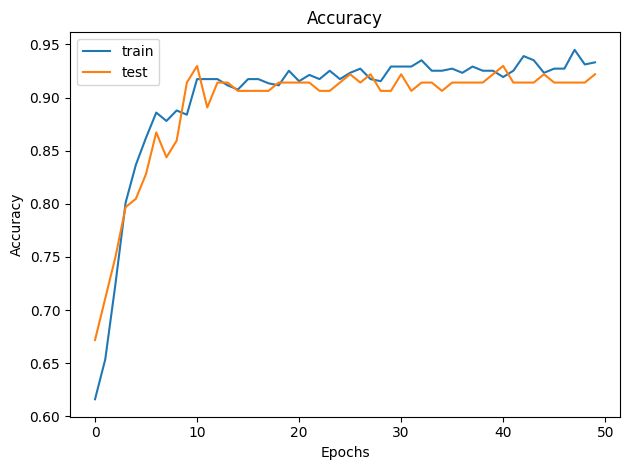

In [19]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Accuracy")
plt.legend(['train','test'],loc='upper left')
plt.tight_layout()
plt.show()

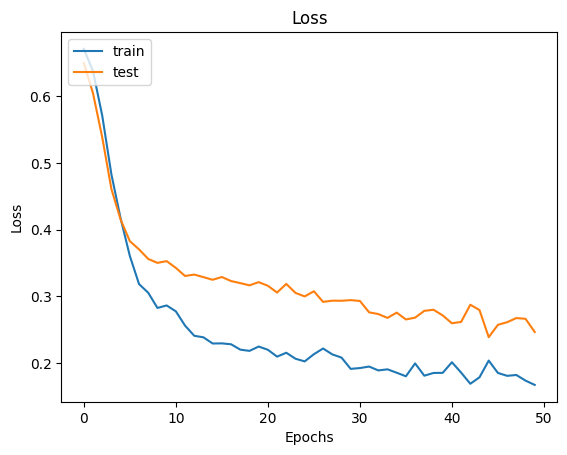

In [20]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Loss")
plt.legend(['train','test'],loc='upper left')
plt.show()

In [21]:
print(df.class_names)

['apple', 'orange']
